# P11 — Benchmark das clusterizações: Leiden × NMF

**Pergunta.** O pipeline novo (programas de NMF de Yasumizu et al., 2024, P10)
descreve as células melhor que o anterior (Leiden 1,0 sobre o ComBat, P08,
anotado no P09)?

**As partições comparadas**, todas sobre os mesmos dados corrigidos pelo ComBat:

| partição | o que é |
| --- | --- |
| Leiden 1,0 | o pipeline anterior (P08), 19 clusters, anotado no P09 |
| Leiden 0,6 | o mesmo grafo com 14 clusters, o número de programas da NMF: separa o efeito do método do efeito do número de grupos |
| NMF k = 14 | o pipeline novo: programa dominante da NMF de novo, anotado no P10 |
| NMF k = 9 | a outra escolha reprodutível de k (sensibilidade) |
| NMF projetada | programa dominante entre os 12 programas publicados do atlas |

**As métricas**, em cinco grupos. As réguas de concordância não dependem de
nenhuma das partições:

* **concordância** (ARI e NMI) com o tipo L2 e L1 do atlas (mapeamento
  Symphony, só nas células CD4⁺ pelo Azimuth) e com o Azimuth do Cell Ranger (7
  grupos, todas as células com rótulo);
* **robustez**: ARI entre 3 sementes e entre a partição completa e a refeita em
  subamostras de 80% (3 vezes);
* **técnica**: 1 − η² dos UMIs dentro da biblioteca (quanto menos a partição
  segue a profundidade, melhor), número efetivo de pacientes por grupo e
  1 − fração das células em grupos dominados por uma biblioteca;
* **marcadores**: AUROC média dos 10 genes mais específicos de cada grupo;
* **anotação**: concordância dos rótulos do pipeline com o L1 do atlas.

Como no P07, cada métrica é escalonada (min-max) entre as partições. O score
de cada grupo é a média das suas métricas, e o geral é a média dos grupos, com
pesos iguais (definido antes de ver os resultados).

Limite de inferência: 7 pacientes, 14 bibliotecas.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import json
import warnings
warnings.filterwarnings("ignore")

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from sklearn.metrics import adjusted_rand_score

from functions import anotacao as an, atlas, benchplots as bp, clustbench as cb, config, fmt as F, io, nmf, plotting
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)
sc.settings.verbosity = 0

NB = "P11_benchmark_clusterizacao"
log = IssueLog(NB)
INK = plotting.INK

In [2]:
main = ad.read_h5ad(io.data_path("P05_integracao", "reseq_raw_integrado", "h5ad"))
integ = ad.read_h5ad(io.data_path("P07_benchmark_integracao", "integracao_escolhida", "h5ad"))
keys = main.obs["cell_key"].astype(str).to_numpy()
rot = pd.read_parquet(io.data_path("P08_clusterizacao", "clusters", "parquet")).set_index("cell_key").reindex(keys)
anot = pd.read_parquet(io.data_path("P09_anotacao", "anotacao", "parquet")).set_index("cell_key").reindex(keys)
prog = pd.read_parquet(io.data_path("P10_nmf_programas", "programas", "parquet")).set_index("cell_key").reindex(keys)
sweep = pd.read_parquet(config.HEAVY_OUT / "P08_clusterizacao" / "leiden_sweep.parquet")
N = len(keys)
lib = main.obs["library_id"].astype(str).to_numpy()
pat = main.obs["patient"].astype(str).to_numpy()
umis = main.obs["total_counts"].to_numpy()

PARTS = {
    "leiden10": rot["leiden_final"].astype(str).to_numpy(),
    "leiden06": rot["leiden_r0.6"].astype(str).to_numpy(),
    "nmf14": prog["nmf14_programa"].astype(str).to_numpy(),
    "nmf9": prog["nmf9_programa"].astype(str).to_numpy(),
    "proj12": prog["proj_programa"].astype(str).to_numpy(),
}
NOMES = {"leiden10": "Leiden 1,0 (anterior)", "leiden06": "Leiden 0,6 (14 clusters)", "nmf14": "NMF k = 14 (novo)",
         "nmf9": "NMF k = 9", "proj12": "NMF projetada (atlas)"}
ROTULOS = {"leiden10": anot["anotacao"].to_numpy(), "nmf14": prog["nmf14_rotulo"].to_numpy(),
           "proj12": prog["proj_rotulo"].to_numpy()}
n_grupos = {k: int(pd.Series(v).nunique()) for k, v in PARTS.items()}
print(f"{F.n(N)} células · {plotting.N_DESIGN}; grupos por partição: "
      + "; ".join(f"{NOMES[k]} {n}" for k, n in n_grupos.items()))

35.247 células · 14 bibliotecas · 7 pacientes; grupos por partição: Leiden 1,0 (anterior) 19; Leiden 0,6 (14 clusters) 14; NMF k = 14 (novo) 14; NMF k = 9 9; NMF projetada (atlas) 12


## 1. Concordância com as réguas independentes

In [3]:
cd4 = anot["azimuth_grupo"].isin(["CD4 naive", "CD4 memória", "Treg"]).to_numpy() & anot["atlas_L1"].notna().to_numpy()
azg = anot["azimuth_grupo"].where(anot["azimuth_grupo"].astype(str) != "nan").to_numpy()
M = {}
for k, p in PARTS.items():
    r2, n2 = cb.ari_nmi(p, anot["atlas_L2"].to_numpy(), cd4)
    r1, n1 = cb.ari_nmi(p, anot["atlas_L1"].to_numpy(), cd4)
    ra, na = cb.ari_nmi(p, azg)
    M[k] = {"ARI atlas L2": r2, "NMI atlas L2": n2, "ARI atlas L1": r1, "NMI atlas L1": n1,
            "ARI Azimuth": ra, "NMI Azimuth": na}
print(f"células CD4⁺ (Azimuth) mapeadas no atlas: {F.n(cd4.sum())}; com Azimuth: {F.n(pd.notna(azg).sum())}")
pd.DataFrame(M).T.rename(index=NOMES).round(3)

células CD4⁺ (Azimuth) mapeadas no atlas: 32.340; com Azimuth: 33.588


,ARI atlas L2,NMI atlas L2,ARI atlas L1,NMI atlas L1,ARI Azimuth,NMI Azimuth
"Leiden 1,0 (anterior)",0.144,0.250,0.176,0.257,0.091,0.244
"Leiden 0,6 (14 clusters)",0.151,0.253,0.195,0.275,0.111,0.262
NMF k = 14 (novo),0.231,0.276,0.246,0.241,0.159,0.249
NMF k = 9,0.236,0.262,0.293,0.258,0.218,0.279
NMF projetada (atlas),0.214,0.209,0.220,0.160,0.374,0.241


## 2. Robustez

Sementes: o Leiden nas 3 sementes do P08 e a NMF nas 3 sementes da varredura
do P10. A projeção é determinística (W fixa, cada célula projetada sozinha) e
fica de fora. Subamostras de 80%: o Leiden é refeito sobre o embedding do
ComBat das células sorteadas; a NMF é reajustada na subamostra e todas as
células são projetadas na W resultante.

In [4]:
def leiden_seeds(r):
    return cb.mean_pairwise_ari([sweep[f"leiden_r{r:g}_s{s}"].to_numpy() for s in (0, 1, 2)])


def nmf_seeds(k):
    return cb.mean_pairwise_ari([nmf.dominant(nmf.normalize(*[np.load(nmf.CACHE / "varredura" / f"nmf_k{k}_s{s}.npz")[x]
                                                              for x in ("H", "W")])[0])[0] for s in nmf.SEEDS])


def leiden_sub(r, full, reps=3, frac=0.8):
    out = []
    for i in range(reps):
        idx = np.sort(np.random.default_rng(100 + i).choice(N, int(frac * N), replace=False))
        t = ad.AnnData(obs=pd.DataFrame(index=np.arange(len(idx)).astype(str)))
        t.obsm["X_emb"] = np.asarray(integ.obsm["X_emb"])[idx]
        sc.pp.neighbors(t, n_neighbors=15, use_rep="X_emb", random_state=0)
        sc.tl.leiden(t, resolution=r, random_state=0)
        out.append(adjusted_rand_score(full[idx], t.obs["leiden"].astype(str)))
    return float(np.mean(out))


Xn = np.load(nmf.CACHE / "entradas" / "X_nmf.npy")


def nmf_sub(k, full, reps=3, frac=0.8):
    out = []
    for i in range(reps):
        f = nmf.CACHE / "estabilidade" / f"sub{i}_k{k}.npz"
        if f.exists():
            Hs = np.load(f)["H"]
            W = np.load(f)["W"]
        else:
            idx = np.sort(np.random.default_rng(100 + i).choice(N, int(frac * N), replace=False))
            _, W, _, _ = nmf.fit(Xn[idx], k, seed=100 + i)
            Hs = nmf.project_fixed(Xn, W)
        d = nmf.dominant(nmf.normalize(Hs, W)[0])[0]
        out.append(adjusted_rand_score(full, d.astype(str)))
    return float(np.mean(out))


full14 = np.array([p[1:] for p in PARTS["nmf14"]])
full9 = np.array([p[1:] for p in PARTS["nmf9"]])
R = {"leiden10": {"ARI entre sementes": leiden_seeds(1.0), "ARI em subamostra": leiden_sub(1.0, PARTS["leiden10"])},
     "leiden06": {"ARI entre sementes": leiden_seeds(0.6), "ARI em subamostra": leiden_sub(0.6, PARTS["leiden06"])},
     "nmf14": {"ARI entre sementes": nmf_seeds(14), "ARI em subamostra": nmf_sub(14, full14)},
     "nmf9": {"ARI entre sementes": nmf_seeds(9), "ARI em subamostra": nmf_sub(9, full9)},
     "proj12": {"ARI entre sementes": np.nan, "ARI em subamostra": np.nan}}
pd.DataFrame(R).T.rename(index=NOMES).round(3)

,ARI entre sementes,ARI em subamostra
"Leiden 1,0 (anterior)",0.576,0.474
"Leiden 0,6 (14 clusters)",0.540,0.408
NMF k = 14 (novo),0.998,0.935
NMF k = 9,0.998,0.978
NMF projetada (atlas),NaN,NaN


## 3. Técnica e marcadores

In [5]:
hv = main.var["highly_variable"].to_numpy()
sym = main.var["gene_symbol"].astype(str).to_numpy()
cols = np.flatnonzero(hv | np.isin(sym, an.panel_genes()))
Xm = main.X[:, cols]
T, AUC = {}, {}
for k, p in PARTS.items():
    auc, por = cb.marker_auroc(Xm, p)
    AUC[k] = por
    T[k] = {"1 − η² profundidade": 1 - cb.depth_eta2(p, umis, lib),
            "pacientes por grupo": cb.patient_mixing(p, pat),
            "1 − fração em grupo de 1 biblioteca": 1 - cb.single_library_fraction(p, lib),
            "AUROC dos marcadores": auc}
pd.DataFrame(T).T.rename(index=NOMES).round(3)

,1 − η² profundidade,pacientes por grupo,1 − fração em grupo de 1 biblioteca,AUROC dos marcadores
"Leiden 1,0 (anterior)",0.411,5.629,0.878,0.766
"Leiden 0,6 (14 clusters)",0.738,5.869,0.875,0.796
NMF k = 14 (novo),0.669,5.689,0.956,0.772
NMF k = 9,0.932,6.153,1.000,0.776
NMF projetada (atlas),0.963,5.636,0.792,0.776


## 4. Anotação contra o atlas

Os rótulos de cada pipeline traduzidos para o L1 do atlas (naive, Tcm, Tem,
Temra, Treg). Rótulos sem equivalente (ativadas, transição, programas
técnicos) ficam de fora; a cobertura diz que fração das células CD4⁺ entrou
na conta.

In [6]:
A = {}
for k in PARTS:
    if k in ROTULOS:
        A[k] = cb.annotation_agreement(ROTULOS[k], anot["atlas_L1"].to_numpy(), cd4, an.TO_ATLAS_L1)
    else:
        A[k] = {"acuracia": np.nan, "kappa": np.nan, "cobertura": np.nan}
pd.DataFrame(A).T.rename(index=NOMES).round(3)

,acuracia,kappa,cobertura
"Leiden 1,0 (anterior)",0.792,0.652,0.732
"Leiden 0,6 (14 clusters)",NaN,NaN,NaN
NMF k = 14 (novo),0.804,0.661,0.685
NMF k = 9,NaN,NaN,NaN
NMF projetada (atlas),0.698,0.399,0.822


## 5. O resultado no formato do P07

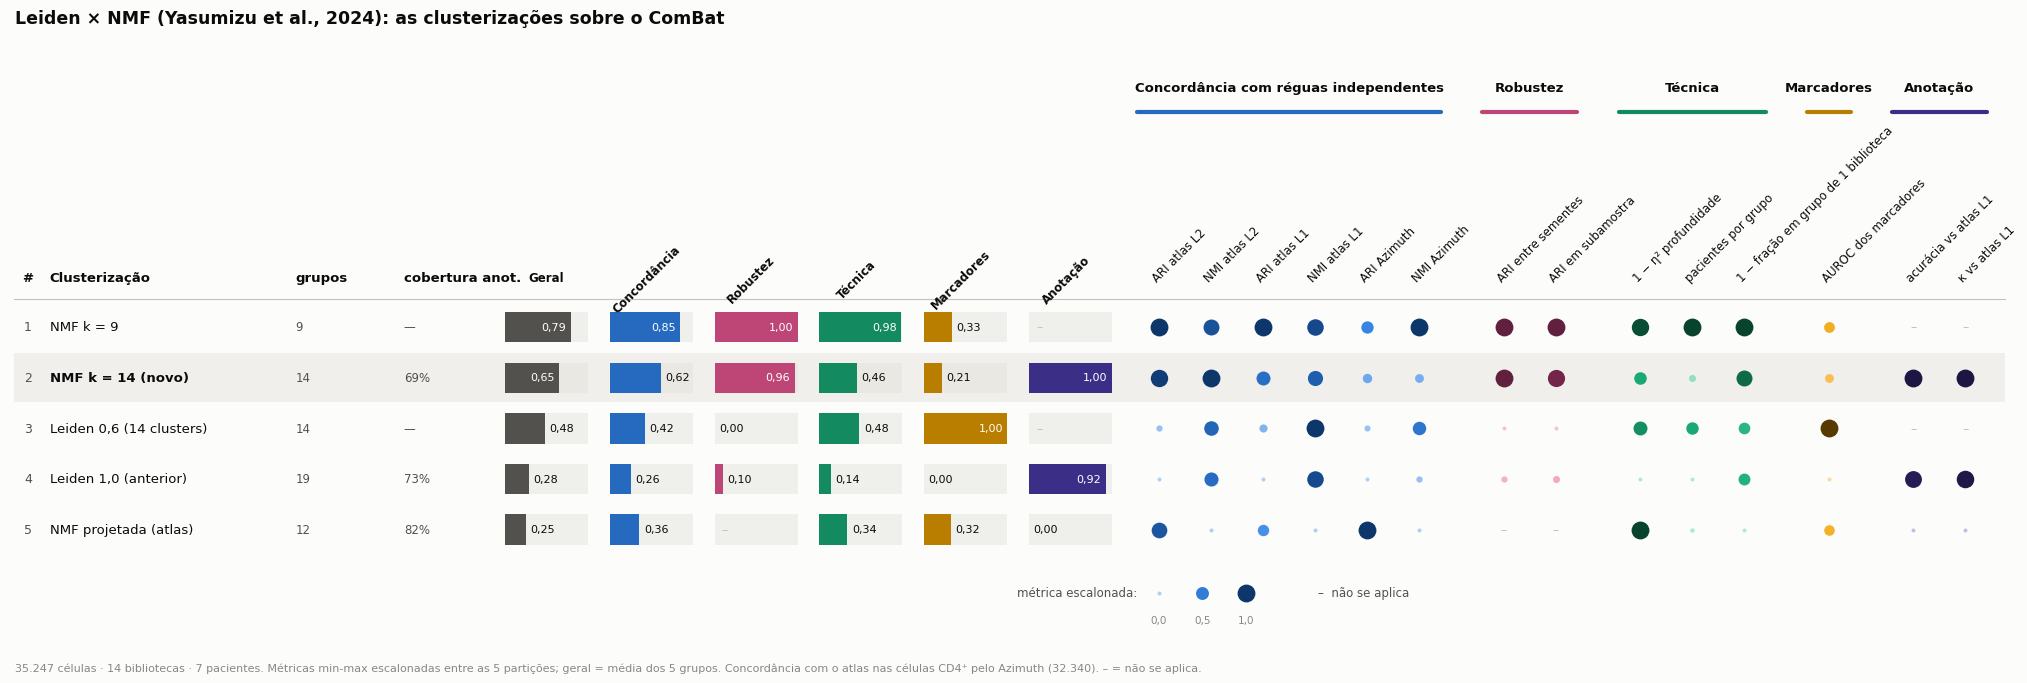

,ARI atlas L2,NMI atlas L2,ARI atlas L1,NMI atlas L1,ARI Azimuth,NMI Azimuth,ARI entre sementes,ARI em subamostra,1 − η² profundidade,pacientes por grupo,1 − fração em grupo de 1 biblioteca,AUROC dos marcadores,acurácia vs atlas L1,κ vs atlas L1
"Leiden 1,0 (anterior)",0.144,0.250,0.176,0.257,0.091,0.244,0.576,0.474,0.411,5.629,0.878,0.766,0.792,0.652
"Leiden 0,6 (14 clusters)",0.151,0.253,0.195,0.275,0.111,0.262,0.540,0.408,0.738,5.869,0.875,0.796,NaN,NaN
NMF k = 14 (novo),0.231,0.276,0.246,0.241,0.159,0.249,0.998,0.935,0.669,5.689,0.956,0.772,0.804,0.661
NMF k = 9,0.236,0.262,0.293,0.258,0.218,0.279,0.998,0.978,0.932,6.153,1.000,0.776,NaN,NaN
NMF projetada (atlas),0.214,0.209,0.220,0.160,0.374,0.241,NaN,NaN,0.963,5.636,0.792,0.776,0.698,0.399


In [7]:
GRUPOS = [("Concordância com réguas independentes", ["ARI atlas L2", "NMI atlas L2", "ARI atlas L1", "NMI atlas L1",
                                                     "ARI Azimuth", "NMI Azimuth"]),
          ("Robustez", ["ARI entre sementes", "ARI em subamostra"]),
          ("Técnica", ["1 − η² profundidade", "pacientes por grupo", "1 − fração em grupo de 1 biblioteca"]),
          ("Marcadores", ["AUROC dos marcadores"]),
          ("Anotação", ["acurácia vs atlas L1", "κ vs atlas L1"])]
raw = pd.DataFrame({k: {**M[k], **R[k], **T[k], "acurácia vs atlas L1": A[k]["acuracia"],
                        "κ vs atlas L1": A[k]["kappa"]} for k in PARTS}).T
esc = cb.minmax(raw)
res = pd.DataFrame(index=raw.index)
for g, mets in GRUPOS:
    res[g] = esc[mets].mean(axis=1, skipna=True)
res.insert(0, "Geral", res[[g for g, _ in GRUPOS]].mean(axis=1, skipna=True))
io.save_table(raw.rename(index=NOMES), NB, "metricas_brutas", description="Métricas brutas de cada partição")
io.save_table(res.rename(index=NOMES), NB, "resumo", description="Scores por grupo (min-max) e geral, por partição")
info = [("grupos", {k: str(n_grupos[k]) for k in PARTS}),
        ("cobertura anot.", {k: (F.pct(A[k]["cobertura"], 0) if np.isfinite(A[k]["cobertura"]) else "—") for k in PARTS})]
fig = bp.group_table(res, esc, groups=GRUPOS, bars=[("Geral", "Geral")] + [(g, g.split(" ")[0]) for g, _ in GRUPOS],
                     labels=NOMES, info=info, chosen="nmf14",
                     title="Leiden × NMF (Yasumizu et al., 2024): as clusterizações sobre o ComBat",
                     note=f"{F.n(N)} células · {plotting.N_DESIGN}. Métricas min-max escalonadas entre as {len(raw)} partições; "
                          "geral = média dos 5 grupos. Concordância com o atlas nas células CD4⁺ pelo Azimuth "
                          f"({F.n(cd4.sum())}). – = não se aplica.")
plotting.savefig(fig, NB, "tabela_resumo", description="Tabela-resumo das clusterizações (formato do P07)",
                 data=raw.join(res).rename(index=NOMES).reset_index(), data_index=False)
plt.show()
raw.rename(index=NOMES).round(3)

## 6. Que estados do atlas cada método isola

Para cada tipo L2 do atlas, o F1 do melhor grupo da partição (2·|tipo ∩
grupo| / (|tipo| + |grupo|)): perto de 1, o método tem um grupo que é
praticamente aquele tipo.

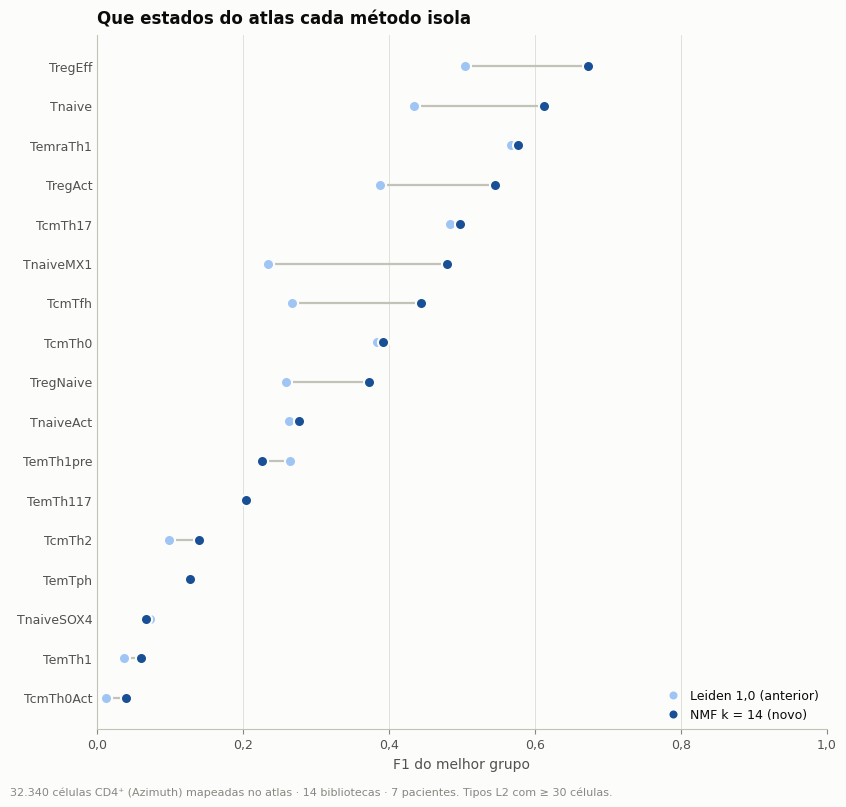

In [8]:
L2 = anot["atlas_L2"].to_numpy()


def best_f1(part):
    out = {}
    for t in atlas.L2:
        m = cd4 & (L2 == t)
        if m.sum() < 30:
            continue
        ct = pd.Series(part[m]).value_counts()
        sizes = pd.Series(part[cd4]).value_counts()
        out[t] = float((2 * ct / (m.sum() + sizes.reindex(ct.index))).max())
    return pd.Series(out)


f1 = pd.DataFrame({k: best_f1(PARTS[k]) for k in ("leiden10", "nmf14")})
f1 = f1.loc[f1.max(axis=1).sort_values().index]
io.save_table(f1.rename(columns=NOMES), NB, "f1_por_tipo_atlas", description="F1 do melhor grupo para cada tipo L2 do atlas")
fig, ax = plt.subplots(figsize=(8.5, 0.36 * len(f1) + 1.8))
plotting.dumbbell(ax, f1["leiden10"], f1["nmf14"], labels=list(f1.index[::-1]), xlabel="F1 do melhor grupo",
                  before_label=NOMES["leiden10"], after_label=NOMES["nmf14"], legend_loc="lower right")
ax.set_xlim(0, 1)
plotting.decimals(ax, "x", 1)
ax.set_title("Que estados do atlas cada método isola")
plotting.note(fig, f"{F.n(cd4.sum())} células CD4⁺ (Azimuth) mapeadas no atlas · {plotting.N_DESIGN}. Tipos L2 com ≥ 30 células.",
              y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "f1_por_tipo_atlas", description="F1 do melhor grupo por tipo do atlas, Leiden × NMF",
                 data=f1.rename(columns=NOMES).reset_index(), data_index=False)
plt.show()

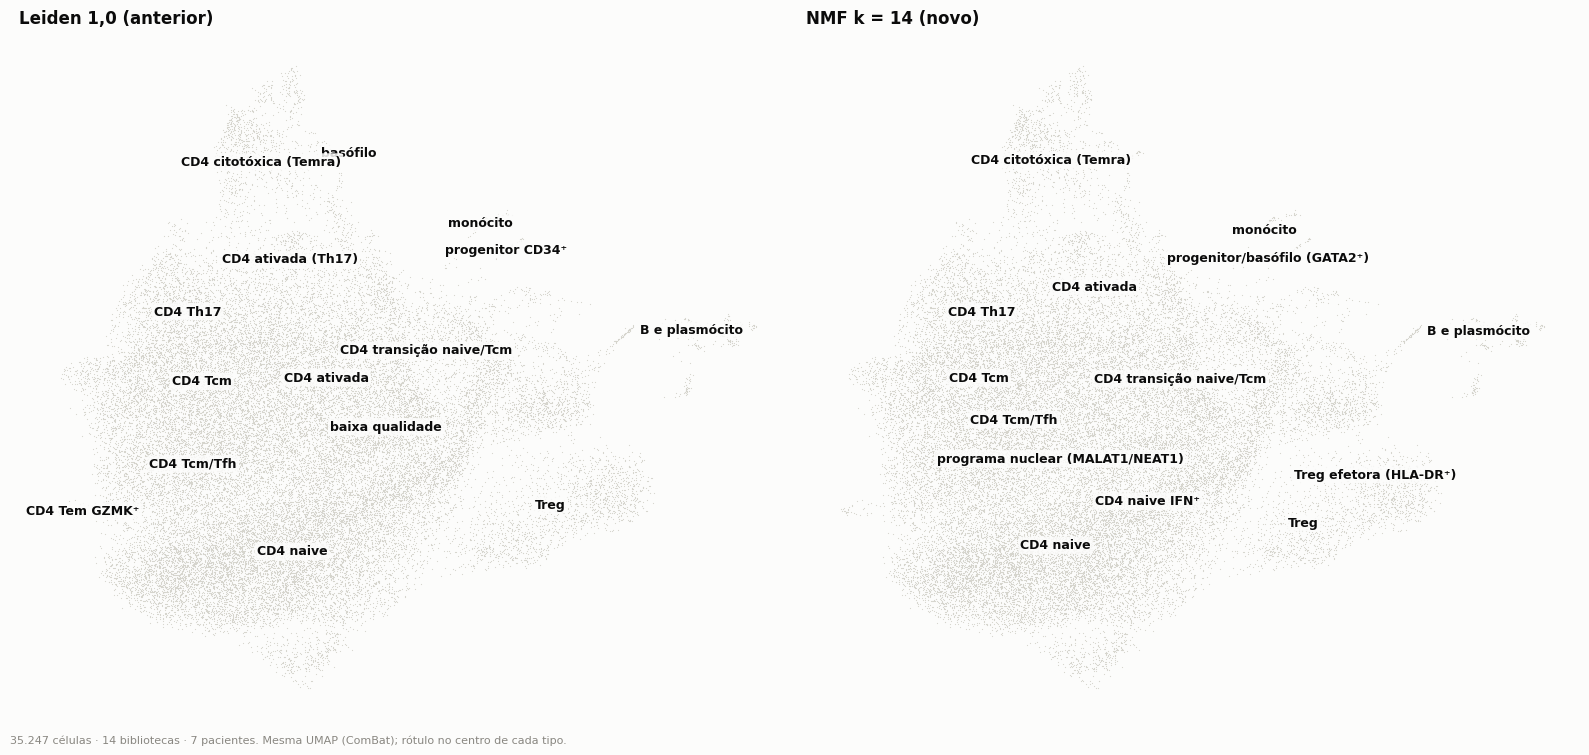

In [9]:
um = integ.obsm["X_umap"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 7.4))
plotting.umap_labeled(a1, um, ROTULOS["leiden10"].astype(str), s=0.7, title=NOMES["leiden10"])
plotting.umap_labeled(a2, um, ROTULOS["nmf14"].astype(str), s=0.7, title=NOMES["nmf14"])
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Mesma UMAP (ComBat); rótulo no centro de cada tipo.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "umap_leiden_x_nmf", description="Anotação do Leiden e da NMF na mesma UMAP",
                 data=pd.crosstab(ROTULOS["nmf14"], ROTULOS["leiden10"]).reset_index(), data_index=False)
plt.show()

## Problemas encontrados

In [10]:
melhor = res["Geral"].idxmax()
issues_txt = "; ".join(f"{NOMES[k]} {F.f(v, 2)}" for k, v in res["Geral"].sort_values(ascending=False).items())
log.add("INFO", "resultado", f"[RESULTADO] maior score geral: {NOMES[melhor]}",
        evidence=issues_txt, impact="ver a conclusão: os grupos de métricas puxam em direções diferentes",
        recommendation="nenhuma")
log.add("MINOR", "número de grupos", "ARI e NMI dependem do número de grupos de cada partição",
        evidence=", ".join(f"{NOMES[k]}: {n_grupos[k]}" for k in PARTS),
        impact="por isso a linha Leiden 0,6, com o mesmo número de grupos da NMF k = 14",
        recommendation="comparar o novo pipeline com as duas linhas do Leiden")
log.add("MINOR", "régua do atlas", "o atlas é de 5′ v2, em doenças autoimunes; os nossos dados são 3′ v3, com estímulo",
        evidence=f"1.177 de 1.271 genes do atlas presentes; células CD4⁺ comparáveis: {F.n(cd4.sum())}",
        impact="estados próprios do estímulo pelo M. leprae não existem no atlas e caem no tipo mais próximo",
        recommendation="ler a concordância com o atlas como validação dos estados de repouso, não dos ativados")
issues = log.save()
print(log.summary().to_string())
show(issues)

severity
CRITICAL    0
MAJOR       0
MINOR       2
INFO        1


severity,location,problem,evidence,impact,recommendation
MINOR,número de grupos,ARI e NMI dependem do número de grupos de cada partição,"Leiden 1,0 (anterior): 19, Leiden 0,6 (14 clusters): 14, NMF k = 14 (novo): 14, NMF k = 9: 9, NMF projetada (atlas): 12","por isso a linha Leiden 0,6, com o mesmo número de grupos da NMF k = 14",comparar o novo pipeline com as duas linhas do Leiden
MINOR,régua do atlas,"o atlas é de 5′ v2, em doenças autoimunes; os nossos dados são 3′ v3, com estímulo",1.177 de 1.271 genes do atlas presentes; células CD4⁺ comparáveis: 32.340,estados próprios do estímulo pelo M. leprae não existem no atlas e caem no tipo mais próximo,"ler a concordância com o atlas como validação dos estados de repouso, não dos ativados"
INFO,resultado,[RESULTADO] maior score geral: NMF k = 9,"NMF k = 9 0,79; NMF k = 14 (novo) 0,65; Leiden 0,6 (14 clusters) 0,48; Leiden 1,0 (anterior) 0,28; NMF projetada (atlas) 0,25",ver a conclusão: os grupos de métricas puxam em direções diferentes,nenhuma


## Conclusão

**O pipeline novo (NMF k = 14) supera o anterior (Leiden 1,0)** no score
geral (0,65 contra 0,28) e também o Leiden com o mesmo número de grupos
(Leiden 0,6: 0,48). Por grupo de métricas:

* **concordância com o atlas:** ARI 0,23 contra 0,14 no L2 e 0,25 contra 0,18
  no L1. A NMF isola melhor a maioria dos estados do atlas: naive com
  interferon (F1 0,48 contra 0,23), Treg efetora (0,67 contra 0,50), Tfh (0,44
  contra 0,27);
* **robustez:** ARI de 0,94 em subamostras de 80%, contra 0,47. Entre
  sementes, 0,998 contra 0,58, mas a reprodutibilidade entre sementes foi o
  critério da escolha de k, então essa linha é alta por construção. A da
  subamostra não é;
* **técnica:** a NMF segue menos a profundidade que o Leiden 1,0 (η² 0,33
  contra 0,59, a diferença vem dos clusters de baixa qualidade do Leiden) e
  tem menos células em grupos dominados por uma biblioteca;
* **marcadores:** o Leiden 0,6 tem os marcadores mais específicos (AUROC
  0,80 contra 0,77). Fronteiras rígidas de grafo dão grupos mais "limpos" de
  marcador;
* **anotação:** empate com o atlas (80,4% contra 79,2%), com cobertura um pouco
  menor na NMF (69% contra 73% das células CD4⁺ têm rótulo comparável).

A NMF com k = 9 tira a maior nota geral (0,79), mas não foi anotada: é
comparada sem o grupo "anotação". O resultado diz que menos programas, mais
amplos, concordam ainda mais com as réguas.

**O que isso significa.** Para estes dados, a NMF do artigo descreve as
células de forma mais estável e mais próxima de uma referência independente
do que o Leiden. O ganho vem sobretudo da robustez e de estados que o grafo
mistura. O preço é que metade das células é mistura de programas: o
programa dominante é um resumo, e as análises devem usar as atividades H.